# 06 - Evaluasi Test Final

Test April-Juni 2026 dibuka sekali. Tidak ada tuning, refit, atau perubahan
threshold. Artefak final dan threshold berasal dari lock pre-test-lock.

Model dievaluasi:
- A: LogReg original features termasuk volume_hub_hari (leaky, not deployable),
- B: LogReg original features tanpa volume_hub_hari,
- C: final LogReg + lag volume, sigmoid, threshold 0,090 / 0,523.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import siapkan_fitur, tambah_volume_lag

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BIAYA_FN = 50_000
BIAYA_FP = 5_000

metadata = json.loads((ROOT / "artifacts" / "metadata.json").read_text(encoding="utf-8"))
config = json.loads((ROOT / "artifacts" / "thresholds.json").read_text(encoding="utf-8"))
model_final = joblib.load(ROOT / "artifacts" / "model.joblib")

# Pembukaan test satu kali.
data = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = data.loc[data["tanggal_pickup"] <= "2025-12-31"].copy()
valid = data.loc[data["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
test = data.loc[data["tanggal_pickup"].between("2026-04-01", "2026-06-30")].copy()
del data

print("Baris test:", len(test))
print("Rentang test:", test["tanggal_pickup"].min().date(), "sampai", test["tanggal_pickup"].max().date())
print("Model final:", metadata["model_version"])
print("Threshold lock:", config["thresholds"])

Baris test: 6744
Rentang test: 2026-04-01 sampai 2026-06-30
Model final: lag-logreg-v1-sigmoid
Threshold lock: {'kabari_pelanggan': 0.09, 'prioritaskan': 0.523}


## Model A dan B

Keduanya dilatih hanya pada train, tanpa tuning. A = fitur asli termasuk
volume_hub_hari; B = fitur asli tanpa kolom itu.

In [2]:
ORIG_NUM_A = ["jam_pickup", "jarak_km", "jumlah_transit", "janji_hari", "berat_kg", "volume_hub_hari"]
ORIG_NUM_B = [k for k in ORIG_NUM_A if k != "volume_hub_hari"]
ORIG_CAT = ["kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]


def latih_baseline(kolom_num):
    prep = ColumnTransformer(
        [
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), kolom_num),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]), ORIG_CAT),
        ]
    )
    model = Pipeline([
        ("preprocessor", prep),
        ("logistic", LogisticRegression(max_iter=2000, random_state=42)),
    ])
    model.fit(train[kolom_num + ORIG_CAT], train["terlambat"])
    return model.predict_proba(test[kolom_num + ORIG_CAT])[:, 1]


prob_A = latih_baseline(ORIG_NUM_A)
prob_B = latih_baseline(ORIG_NUM_B)
y_test = test["terlambat"].to_numpy()

## Model C

Fitur lag dihitung dari tanggal-tanggal sebelum pickup. Untuk awal April,
sumbernya adalah Maret 2026; untuk tanggal berikutnya, hari sebelumnya dalam
data test. Tidak ada kolom terlambat yang dipakai sebagai fitur.

In [3]:
referensi = pd.concat([train, valid, test], ignore_index=True)
test_lag = tambah_volume_lag(test, referensi)
X_test = siapkan_fitur(test_lag, metadata)
prob_C = model_final.predict_proba(X_test)[:, 1]

hasil = []
for nama, proba in [
    ("A. LogReg original incl volume (leaky, not deployable)", prob_A),
    ("B. LogReg original tanpa volume", prob_B),
    ("C. Final LogReg+lag sigmoid", prob_C),
]:
    hasil.append({
        "model": nama,
        "PR-AUC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "test positive rate": y_test.mean(),
    })

tabel_model = pd.DataFrame(hasil)
tabel_model.round(4)

,model,PR-AUC,ROC-AUC,test positive rate
0,"A. LogReg original incl volume (leaky, not dep...",0.3560,0.7452,0.1392
1,B. LogReg original tanpa volume,0.3601,0.7471,0.1392
2,C. Final LogReg+lag sigmoid,0.3608,0.7502,0.1392


## Detail model final pada threshold yang dikunci

In [4]:
th_notify = float(config["thresholds"]["kabari_pelanggan"])
th_prioritas = float(config["thresholds"]["prioritaskan"])
dikabari = prob_C >= th_notify

tp = int(((y_test == 1) & dikabari).sum())
fp = int(((y_test == 0) & dikabari).sum())
fn = int(((y_test == 1) & ~dikabari).sum())
tn = int(((y_test == 0) & ~dikabari).sum())
presisi = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
biaya_model = fn * BIAYA_FN + fp * BIAYA_FP
biaya_nobody = int((y_test == 1).sum()) * BIAYA_FN
biaya_everyone = int((y_test == 0).sum()) * BIAYA_FP

conf = pd.DataFrame(
    confusion_matrix(y_test, dikabari, labels=[0, 1]),
    index=["aktual 0", "aktual 1"],
    columns=["tidak dikabari", "dikabari"],
)

prioritas = prob_C >= th_prioritas
tp_prio = int(((y_test == 1) & prioritas).sum())
presisi_prio = tp_prio / max(int(prioritas.sum()), 1)
recall_prio = tp_prio / max(int((y_test == 1).sum()), 1)
lift_prio = presisi_prio / y_test.mean()

print(f"Notify threshold: {th_notify:.3f}")
print(f"Precision: {presisi:.4f} | Recall: {recall:.4f}")
print(f"Share notified: {dikabari.mean():.2%}")
print(conf)
print(f"Biaya model: Rp{biaya_model:,.0f}")
print(f"Biaya nobody: Rp{biaya_nobody:,.0f}")
print(f"Biaya everyone: Rp{biaya_everyone:,.0f}")
print(f"Prioritas threshold: {th_prioritas:.3f}")
print(f"Prioritas share: {prioritas.mean():.2%} | precision: {presisi_prio:.4f} | recall: {recall_prio:.4f} | lift: {lift_prio:.3f}")

Notify threshold: 0.090
Precision: 0.2039 | Recall: 0.8328
Share notified: 56.87%
          tidak dikabari  dikabari
aktual 0            2752      3053
aktual 1             157       782
Biaya model: Rp23,115,000
Biaya nobody: Rp46,950,000
Biaya everyone: Rp29,025,000
Prioritas threshold: 0.523
Prioritas share: 3.05% | precision: 0.5485 | recall: 0.1203 | lift: 3.940


In [5]:
brier_test = brier_score_loss(y_test, prob_C)
print(f"Brier test: {brier_test:.4f}")

per_bulan = test.assign(bulan=test["tanggal_pickup"].dt.strftime("%Y-%m"), y=y_test, prob=prob_C)
baris_bulan = []
for bulan, grup in per_bulan.groupby("bulan"):
    baris_bulan.append({
        "bulan": bulan,
        "n": len(grup),
        "positive_rate": grup["y"].mean(),
        "PR-AUC": average_precision_score(grup["y"], grup["prob"]),
    })
tabel_bulanan = pd.DataFrame(baris_bulan)
tabel_bulanan.round(4)

Brier test: 0.1053


,bulan,n,positive_rate,PR-AUC
0,2026-04,2301,0.1473,0.3593
1,2026-05,2288,0.1302,0.3475
2,2026-06,2155,0.1401,0.3904


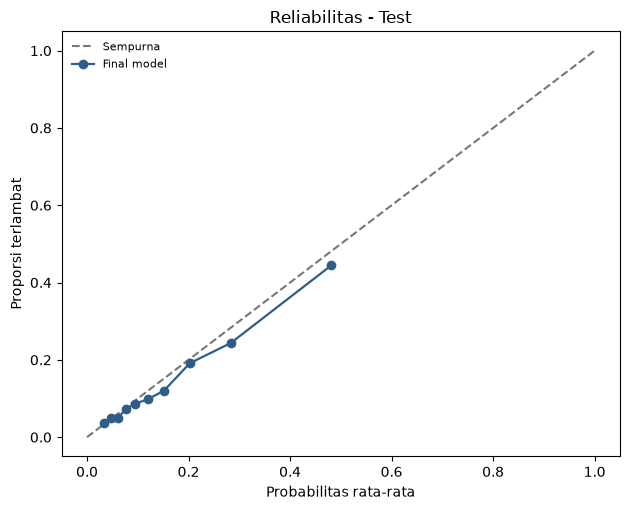

,n,pred,obs
bin,,,
"(0.0166, 0.0418]",675,0.0330,0.0370
"(0.0418, 0.0546]",674,0.0479,0.0490
"(0.0546, 0.0687]",674,0.0617,0.0504
"(0.0687, 0.0847]",675,0.0761,0.0726
"(0.0847, 0.104]",674,0.0941,0.0861
"(0.104, 0.134]",674,0.1193,0.0979
"(0.134, 0.171]",675,0.1514,0.1200
"(0.171, 0.237]",674,0.2026,0.1914
"(0.237, 0.344]",674,0.2829,0.2433


In [6]:
tabel_rel = pd.DataFrame({
    "prob": prob_C,
    "y": y_test,
    "bin": pd.qcut(prob_C, 10, duplicates="drop"),
})
tabel_rel = tabel_rel.groupby("bin", observed=True).agg(
    n=("y", "size"), pred=("prob", "mean"), obs=("y", "mean")
)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Sempurna")
ax.plot(tabel_rel["pred"], tabel_rel["obs"], marker="o", color="#2f5d8a", linewidth=1.6, label="Final model")
ax.set_title("Reliabilitas - Test")
ax.set_xlabel("Probabilitas rata-rata")
ax.set_ylabel("Proporsi terlambat")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_reliabilitas_test.png", dpi=160, bbox_inches="tight")
plt.show()

tabel_rel.round(4)

## Interpretasi model final

Model final adalah pipeline logistik. Koefisien dibaca sebagai arah pengaruh
terhadap log-odds; nilai positif menaikkan risiko, nilai negatif menurunkan.

In [7]:
base = model_final.estimator
while hasattr(base, "estimator") and not hasattr(base, "named_steps"):
    base = base.estimator

logreg = base.named_steps["model"]
nama_fitur = base.named_steps["preprocessor"].get_feature_names_out()
koef = pd.Series(logreg.coef_[0], index=nama_fitur).sort_values()

print("Koefisien positif terbesar:")
print(koef.tail(8).round(3).to_string())
print("\nKoefisien negatif terbesar:")
print(koef.head(8).round(3).to_string())

Koefisien positif terbesar:
kategorikal__kota_tujuan_Pontianak            0.362
numerik__jumlah_transit                       0.363
numerik__volume_hub_kemarin                   0.515
kategorikal__kota_tujuan_Denpasar             0.728
kategorikal__cuaca_saat_pickup_hujan_lebat    0.745
kategorikal__kota_tujuan_Balikpapan           0.782
kategorikal__kota_tujuan_Makassar             0.846
kategorikal__kota_tujuan_Medan                0.916

Koefisien negatif terbesar:
kategorikal__kota_tujuan_Bekasi          -0.721
kategorikal__kota_tujuan_Bogor           -0.632
kategorikal__kota_tujuan_Jakarta         -0.623
kategorikal__kota_tujuan_Tasikmalaya     -0.585
kategorikal__kota_tujuan_Cirebon         -0.559
numerik__janji_hari                      -0.450
kategorikal__cuaca_saat_pickup_cerah     -0.302
kategorikal__cuaca_saat_pickup_berawan   -0.285


## Kunci status test

Status test di metadata diubah menjadi `true` setelah evaluasi selesai.
Model, threshold, dan config tidak diubah.

In [8]:
metadata["test_disentuh"] = True
metadata["test_evaluated_at"] = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
metadata["metrics"]["test"] = {
    "three_models": tabel_model.to_dict(orient="records"),
    "final": {
        "pr_auc": float(average_precision_score(y_test, prob_C)),
        "roc_auc": float(roc_auc_score(y_test, prob_C)),
        "positive_rate": float(y_test.mean()),
        "notify_threshold": th_notify,
        "precision": float(presisi),
        "recall": float(recall),
        "share_notified": float(dikabari.mean()),
        "confusion_matrix": conf.to_dict(),
        "cost_model": int(biaya_model),
        "cost_nobody": int(biaya_nobody),
        "cost_everyone": int(biaya_everyone),
        "brier": float(brier_test),
        "prioritize": {
            "threshold": th_prioritas,
            "share": float(prioritas.mean()),
            "precision": float(presisi_prio),
            "recall": float(recall_prio),
            "lift": float(lift_prio),
        },
        "monthly_pr_auc": tabel_bulanan.to_dict(orient="records"),
    },
}
(ROOT / "artifacts" / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Metadata diperbarui: test_disentuh=true")
print(tabel_model.round(4).to_string(index=False))
print(tabel_bulanan.round(4).to_string(index=False))

Metadata diperbarui: test_disentuh=true
                                                 model  PR-AUC  ROC-AUC  test positive rate
A. LogReg original incl volume (leaky, not deployable)  0.3560   0.7452              0.1392
                       B. LogReg original tanpa volume  0.3601   0.7471              0.1392
                           C. Final LogReg+lag sigmoid  0.3608   0.7502              0.1392
  bulan    n  positive_rate  PR-AUC
2026-04 2301         0.1473  0.3593
2026-05 2288         0.1302  0.3475
2026-06 2155         0.1401  0.3904


Data test April-Juni 2026 sudah dievaluasi satu kali. Model, threshold, dan config
tidak diubah setelah evaluasi.